# Лабораторная работа № 1
## Линейная регрессия и факторный анализ

**Датасет:** Appliances Energy Prediction. **Цель:** расход энергии бытовыми приборами `Appliances`, Wh (Вт·ч).

### 1. Введение

Цель работы — изучить линейную регрессию, обучить модели на реальных данных
и оценить их качество. Необходимо исследовать распределения и корреляции,
выполнить предобработку, рассчитать VIF, сравнить линейную регрессию (OLS),
Lasso и Ridge до и после PCA, а также проанализировать остатки.

`Appliances` — количественная переменная, поэтому логистическая регрессия
для данного набора не требуется. Качество оценивается по трём метрикам:

$$RMSE=\sqrt{\frac1n\sum_i(y_i-\hat y_i)^2},\qquad
R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2},\qquad
MAPE=\frac{100\%}{n}\sum_i\left|\frac{y_i-\hat y_i}{y_i}\right|.$$

RMSE измеряется в Wh, MAPE — в процентах; меньшее значение этих ошибок лучше.
Для безразмерного R² лучше большее значение. При малых значениях цели MAPE
сильно увеличивается, поэтому основным критерием сравнения выбран RMSE.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import warnings

os.environ.setdefault("MPLCONFIGDIR", str(Path(".cache/matplotlib").resolve()))
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor
from threadpoolctl import threadpool_limits

warnings.filterwarnings("error", category=ConvergenceWarning)
thread_limiter = threadpool_limits(limits=1)
sns.set_theme(style="whitegrid", font="DejaVu Sans")
pd.set_option("display.max_columns", 12)
OUT = Path("results")
(OUT / "figures").mkdir(parents=True, exist_ok=True)

def show_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / "figures" / name, dpi=140, bbox_inches="tight")
    plt.show()
    plt.close()

Подключены библиотеки анализа данных, регрессии и PCA. Рисунки сохраняются
в `results/figures`. Несходимость Lasso считается ошибкой: результаты модели
не будут приняты, если оптимизация не завершилась корректно.

### 2. Описание датасета

Выбран [Appliances Energy Prediction на Kaggle](https://www.kaggle.com/datasets/loveall/appliances-energy-prediction).
Набор содержит измерения одного энергоэффективного дома в Бельгии с 11 января
по 27 мая 2016 года, сделанные каждые 10 минут. Исходное исследование опубликовано
Candanedo, Feldheim и Deramaix в 2017 году.

CSV загружен из репозитория автора исследования и включён в проект.
Происхождение и контрольная сумма записаны в `data/source.json`.
Используется исходный набор выбранной публикации Kaggle; совпадение байтов
с конкретной версией архива Kaggle отдельно не проверялось.

| Переменные | Описание |
|---|---|
| `date` | Дата и время измерения |
| `Appliances` | Энергия бытовых приборов, Wh; целевая переменная |
| `lights` | Энергия освещения, Wh |
| `T1`–`T9` | Температура, °C: кухня, гостиная, прачечная, кабинет, ванная, северная наружная сторона, гладильная, детская, спальня родителей |
| `RH_1`–`RH_9` | Влажность в соответствующих местах, % |
| `T_out`, `RH_out` | Наружная температура (°C) и влажность (%) по метеостанции |
| `Press_mm_hg` | Давление, мм рт. ст. |
| `Windspeed`, `Visibility`, `Tdewpoint` | Скорость ветра (м/с), видимость (км), точка росы (°C) |
| `rv1`, `rv2` | Искусственные случайные контрольные переменные |

Погодные измерения метеостанции Chièvres интерполированы до 10-минутного шага.
`Appliances` измеряется в Wh — это энергия за интервал, а не мощность в ваттах.

In [2]:
source = json.loads(Path("data/source.json").read_text(encoding="utf-8"))
data_file = Path("data") / source["file"]
assert hashlib.sha256(data_file.read_bytes()).hexdigest() == source["sha256"]
raw = pd.read_csv(data_file, parse_dates=["date"])
display(raw.head(3))
display(pd.Series({"Строк": len(raw), "Столбцов": raw.shape[1],
                   "Пропусков": raw.isna().sum().sum(),
                   "Дубликатов строк": raw.duplicated().sum(),
                   "rv1 и rv2 совпадают": raw.rv1.equals(raw.rv2)}).to_frame("Значение"))
display(raw.Appliances.describe().to_frame("Appliances, Wh"))

,date,Appliances,lights,T1,RH_1,T2,...,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,...,92.0,7.000000,63.000000,5.3,13.275433,13.275433
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,...,92.0,6.666667,59.166667,5.2,18.606195,18.606195
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,...,92.0,6.333333,55.333333,5.1,28.642668,28.642668


,Значение
Строк,19735
Столбцов,29
Пропусков,0
Дубликатов строк,0
rv1 и rv2 совпадают,True


,"Appliances, Wh"
count,19735.000000
mean,97.694958
std,102.524891
min,10.000000
25%,50.000000
50%,60.000000
75%,100.000000
max,1080.000000


Загружено **19 735 строк и 29 столбцов**. Пропусков и полных дубликатов нет.
Цель принимает значения **10–1080 Wh**, её среднее — **97,69 Wh**,
медиана — **60 Wh**. Нулей в цели нет, поэтому MAPE можно рассчитывать без
особой обработки нулевого знаменателя. `rv1` и `rv2` полностью совпадают.

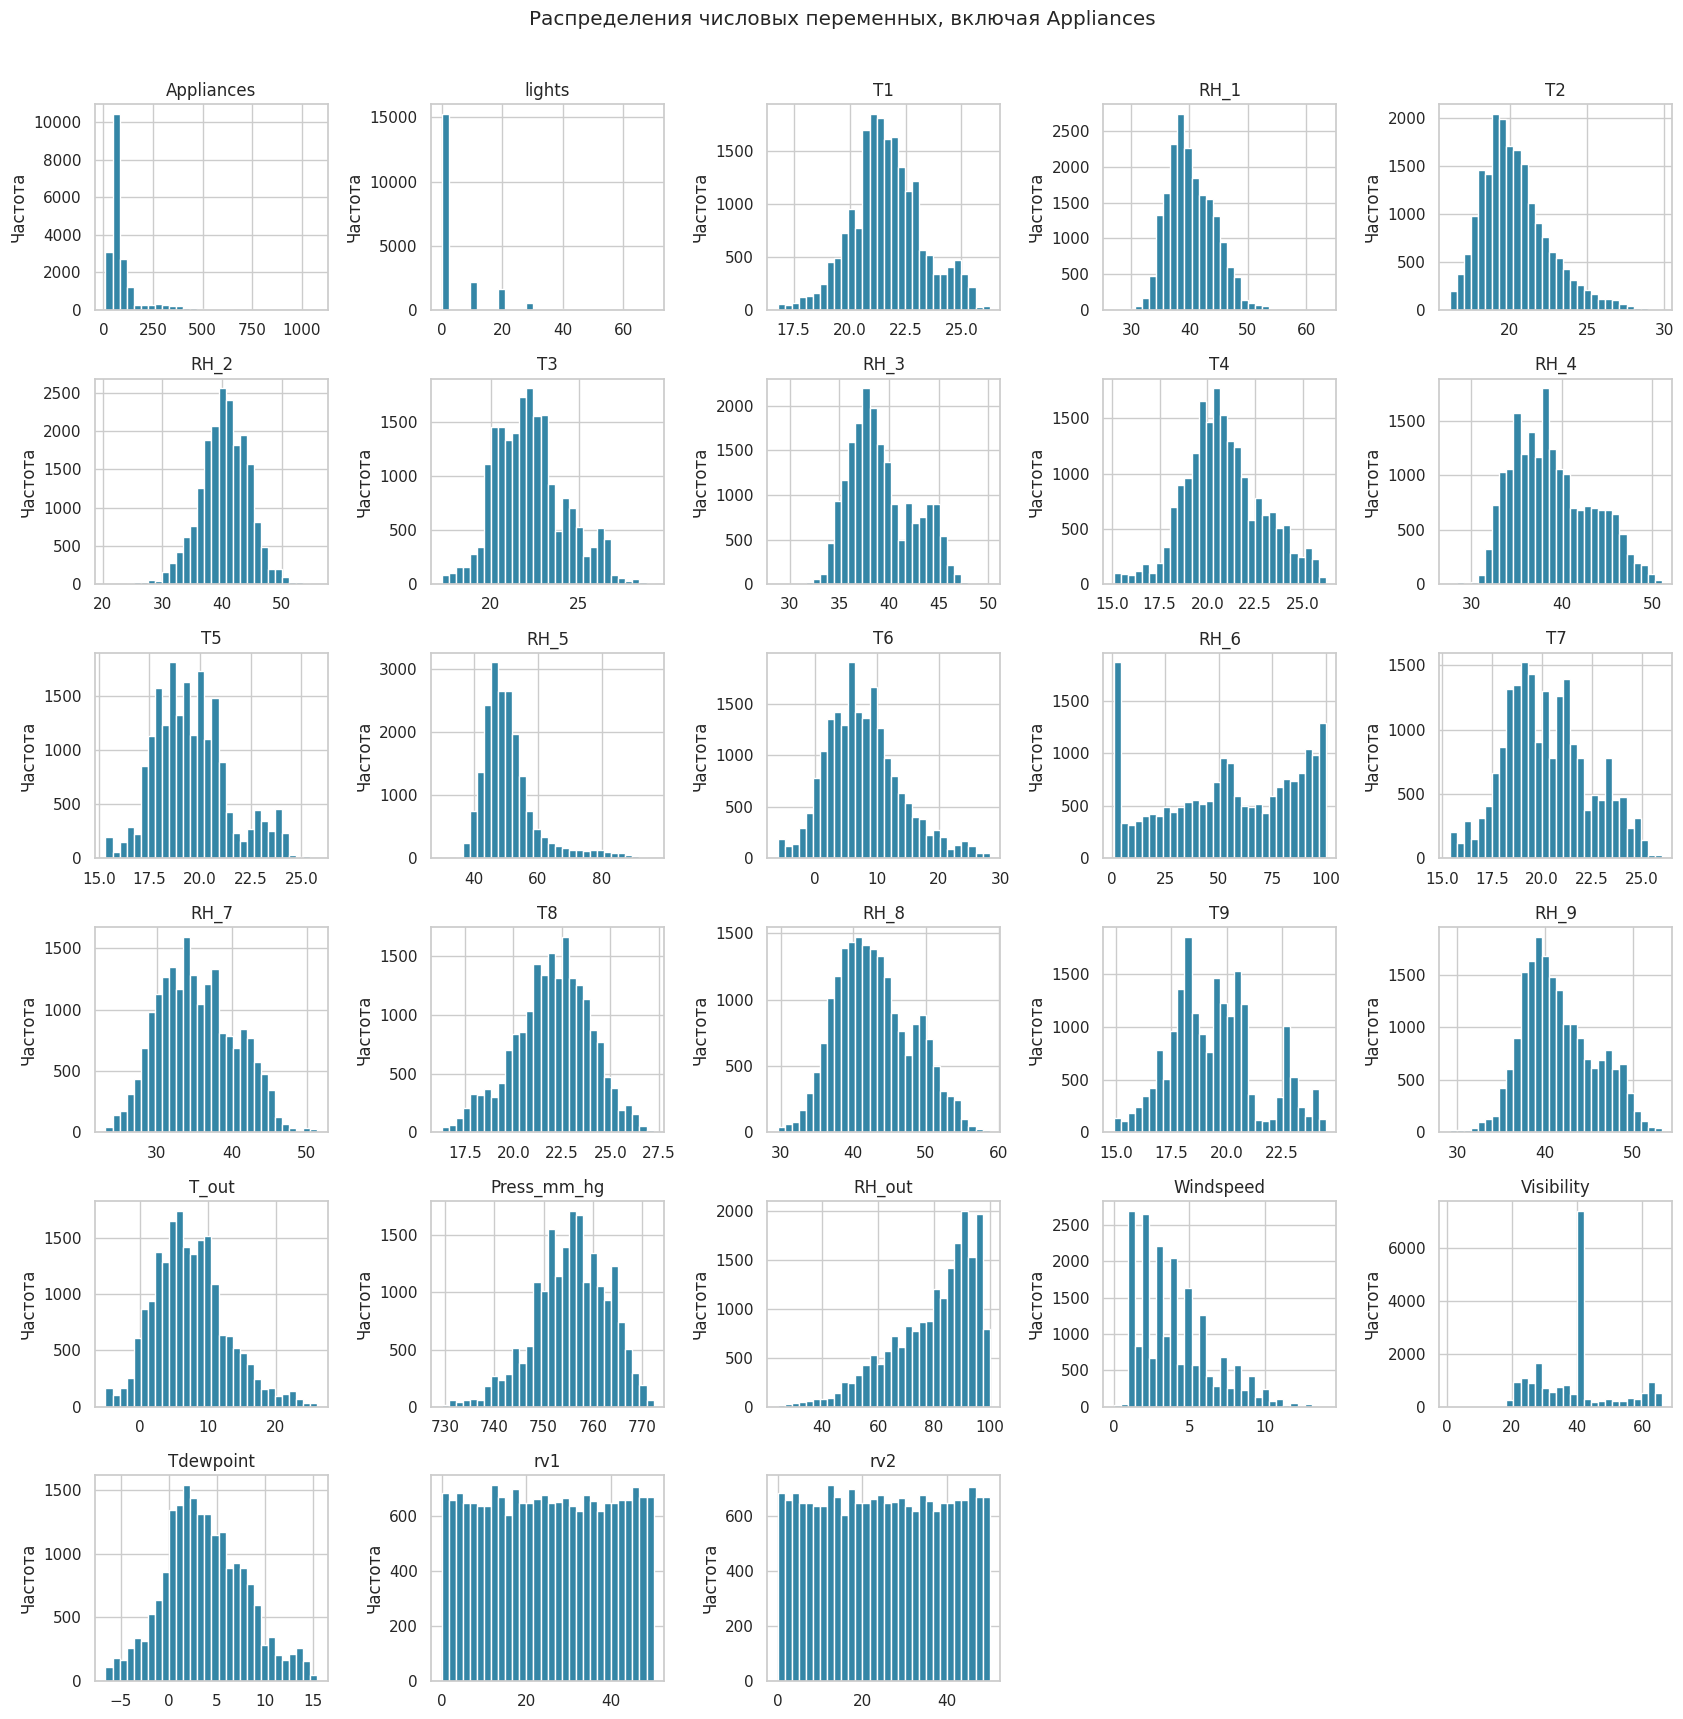

In [3]:
numeric = raw.select_dtypes(include=np.number)
fig, axes = plt.subplots(6, 5, figsize=(17, 17))
for ax, column in zip(axes.flat, numeric.columns):
    ax.hist(numeric[column], bins=30, color="#3486a6")
    ax.set(title=column, ylabel="Частота")
for ax in axes.flat[len(numeric.columns):]:
    ax.axis("off")
fig.suptitle("Распределения числовых переменных, включая Appliances", y=1.01)
show_plot("01_distributions.png")

Распределение `Appliances` имеет длинный правый хвост: небольшое потребление
встречается часто, а крупные пики редки. Эти пики не удаляются как ошибки
без предметного основания. Признаки имеют разные масштабы, поэтому перед
регуляризацией и PCA потребуется стандартизация. Нули у `lights` означают
отсутствие расхода на освещение. Гистограммы `rv1` и `rv2` одинаковы.

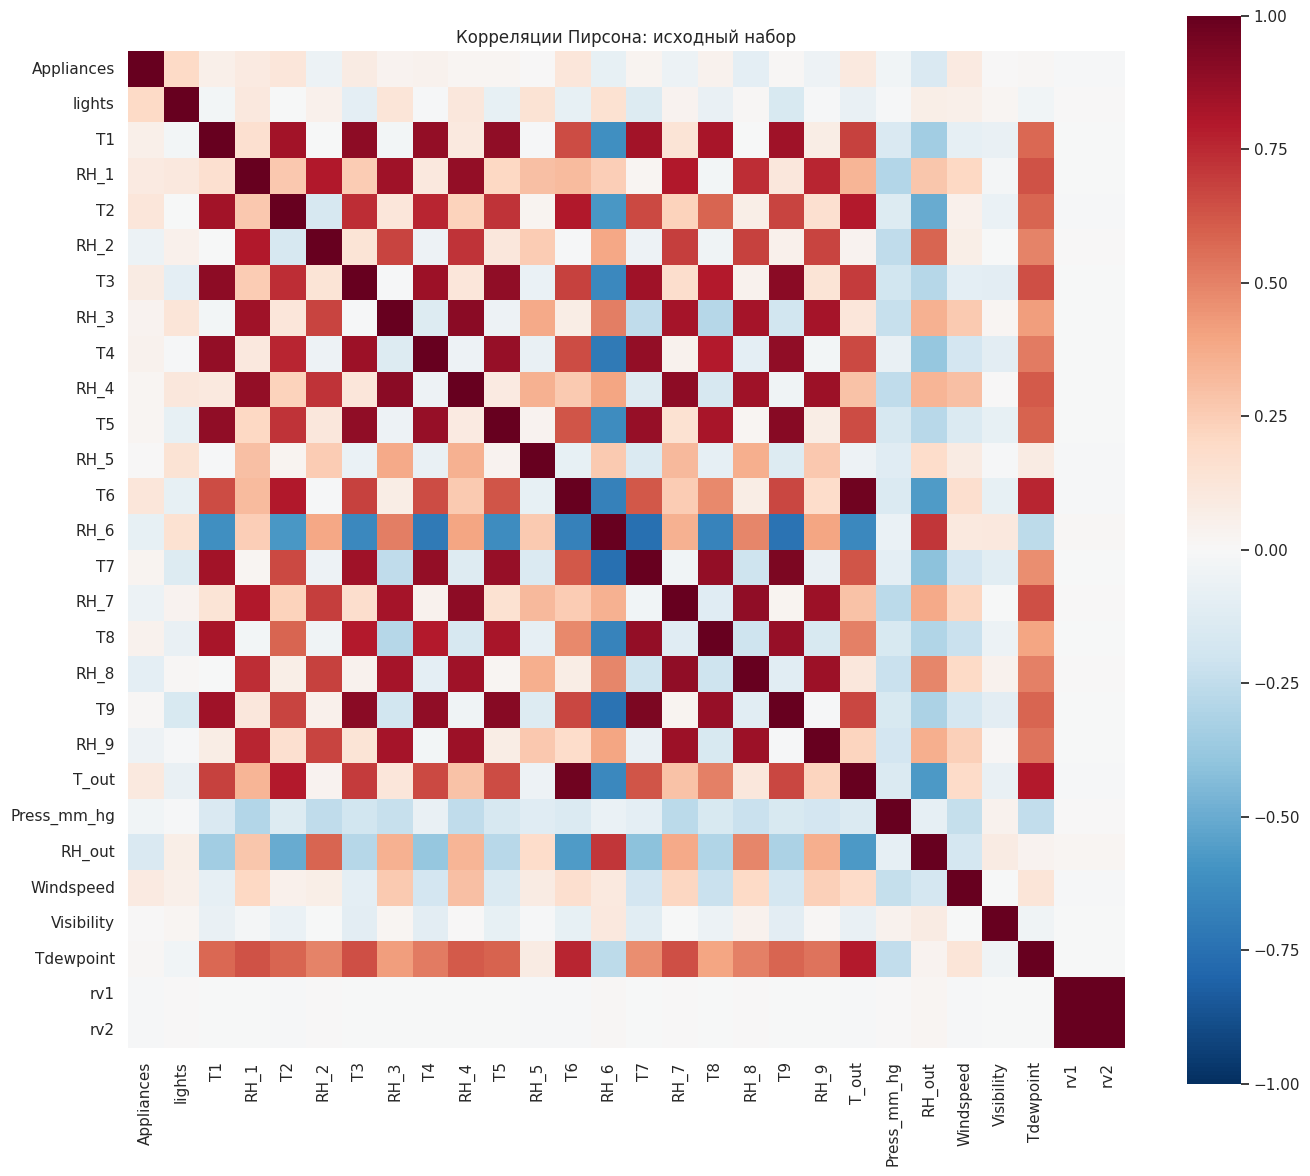

,Корреляция с Appliances
lights,0.197278
RH_out,-0.152282
T2,0.120073
T6,0.117638
T_out,0.099155
RH_8,-0.094039


In [4]:
corr = numeric.corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True)
plt.title("Корреляции Пирсона: исходный набор")
show_plot("02_correlations.png")
target_corr = corr["Appliances"].drop("Appliances").sort_values(key=abs, ascending=False)
display(target_corr.head(6).to_frame("Корреляция с Appliances"))

Матрица отражает сильные связи между температурами и между влажностями,
а также точное дублирование случайных контролей. Парные связи с целью
значительно слабее связей между многими предикторами. VIF ниже проверит
многомерную мультиколлинеарность. Этот раздел описывает весь исходный набор;
признаки не отбираются по величине корреляции с целью. Обучение и настройка
в дальнейшем используют только тренировочные наблюдения.

Сильнейшая парная связь с целью наблюдается у `lights`: **r = 0,197**. Такая слабая связь не позволяет ожидать точного прогноза по одному признаку.

### 3. Подготовка данных

Строки с пропусками удаляются (`dropna`); заполнение средним или медианой
не используется. Полные дубликаты также удаляются. Из предикторов исключаются
`date` — временная метка, и `rv1`, `rv2` — искусственные случайные контроли.
Их исключение основано на описании набора. При совместном включении одинаковых
`rv1` и `rv2` их VIF был бы бесконечным.

Остаются только числовые признаки, поэтому кодирование категорий не требуется.
Данные разделяются с помощью `train_test_split`: **80% train, 20% test**,
`random_state=42`. Стандартизация $z_j=(x_j-\mu_j)/s_j$ входит в `Pipeline`:
параметры вычисляются по train каждого фолда, затем применяются к его проверочной
части. Цель сохраняется в исходных единицах; масштабирование не обучается на тесте.

In [5]:
clean = raw.dropna().drop_duplicates().copy()
X = clean.drop(columns=["date", "Appliances", "rv1", "rv2"])
y = clean["Appliances"]
assert y.gt(0).all()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, random_state=42)
display(pd.DataFrame({"Выборка": ["Train", "Test"],
                      "Строк": [len(X_train), len(X_test)], "Признаков": X.shape[1]}))

,Выборка,Строк,Признаков
0,Train,15788,25
1,Test,3947,25


Очистка не удалила ни одной строки: пропусков и дубликатов нет.
Получены **15 788 тренировочных** и **3947 тестовых** наблюдений с **25 признаками**.
Для всех шести моделей используются одинаковые выборки. Поскольку измерения
упорядочены во времени, случайное разбиение оценивает восстановление потребления
в пределах наблюдаемого периода при известных текущих признаках, а не прогноз
на будущие сутки. Это ограничение учитывается в выводах.

### 4. Ход работы
#### 4.1. Оценка мультиколлинеарности

Для предиктора $x_j$ рассчитывается $VIF_j=1/(1-R_j^2)$, где $R_j^2$
получен при регрессии этого предиктора на остальные со свободным членом.
VIF > 5 служит предупреждением, VIF > 10 указывает на сильную линейную
зависимость. Это ориентировочные пороги. Цель в расчёт VIF не включается;
расчёт выполняется только на train.

In [6]:
def vif(frame):
    matrix = add_constant(StandardScaler().fit_transform(frame))
    return pd.Series([variance_inflation_factor(matrix, i + 1) for i in range(frame.shape[1])],
                     index=frame.columns, name="VIF")

vif_before = vif(X_train)
display(vif_before.sort_values(ascending=False).round(2).to_frame())

,VIF
T_out,150.12
Tdewpoint,88.10
RH_out,49.90
T6,33.75
T2,29.05
T9,28.72
RH_2,22.04
T1,19.98
T7,17.55
RH_4,17.10


Несколько температурных и погодных переменных имеют VIF существенно выше 10:
мультиколлинеарность сохраняется после исключения случайных контролей.
Она снижает устойчивость отдельных коэффициентов OLS. Стандартизация
не устраняет линейные зависимости; далее сравниваются регуляризация и PCA.

**17 из 25 признаков имеют VIF > 10**; максимальное значение у `T_out` — **150,12**. Поэтому проблема касается реальных датчиков, а не только исключённых дублирующихся контролей.

#### 4.2. Регрессии на исходных признаках

OLS минимизирует сумму квадратов ошибок. Ridge добавляет штраф
$\alpha\sum_j\beta_j^2$, Lasso — $\alpha\sum_j|\beta_j|$ и может занулять
коэффициенты. Свободный член не штрафуется. Масштабы `alpha` в этих
реализациях различаются, поэтому их численные значения между методами
не сравниваются.

Используется вложенная кросс-валидация: **5 внешних фолдов** оценивают качество,
**3 внутренних** выбирают `alpha` по RMSE. Для Lasso проверяются 9 значений
от 0,01 до 100, для Ridge — 17 значений от 0,001 до 100 000 по логарифмической
сетке. Затем подбор повторяется на всём train. Тест в настройке не участвует.
Те же фолды и сетки применяются после PCA.

In [7]:
outer_cv = KFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = KFold(n_splits=3, shuffle=True, random_state=17)
scoring = {"RMSE": "neg_root_mean_squared_error", "R2": "r2",
           "MAPE": "neg_mean_absolute_percentage_error"}

def assess_family(use_pca=False):
    candidates = {
        "OLS": (LinearRegression(), {}),
        "Lasso": (Lasso(max_iter=50000), {"reg__alpha": np.logspace(-2, 2, 9)}),
        "Ridge": (Ridge(solver="svd"), {"reg__alpha": np.logspace(-3, 5, 17)}),
    }
    rows, fitted = [], {}
    for name, (regressor, grid) in candidates.items():
        steps = [("scale", StandardScaler())]
        if use_pca:
            steps.append(("pca", PCA(n_components=.95, svd_solver="full")))
        pipe = Pipeline(steps + [("reg", regressor)])
        search = GridSearchCV(pipe, grid, cv=inner_cv, scoring="neg_root_mean_squared_error",
                              n_jobs=1, error_score="raise")
        cv = cross_validate(search, X_train, y_train, cv=outer_cv, scoring=scoring,
                            n_jobs=1, error_score="raise")
        search.fit(X_train, y_train)
        fitted[name] = search.best_estimator_
        pred = fitted[name].predict(X_test)
        rows.append({
            "Признаки": "PCA" if use_pca else "Исходные", "Модель": name,
            "alpha": search.best_params_.get("reg__alpha", np.nan),
            "k": fitted[name]["pca"].n_components_ if use_pca else X.shape[1],
            "CV RMSE": -cv["test_RMSE"].mean(),
            "CV σ RMSE": cv["test_RMSE"].std(ddof=1),
            "CV R²": cv["test_R2"].mean(), "CV MAPE, %": -100 * cv["test_MAPE"].mean(),
            "RMSE, Wh": root_mean_squared_error(y_test, pred), "R²": r2_score(y_test, pred),
            "MAPE, %": 100 * mean_absolute_percentage_error(y_test, pred),
        })
    return pd.DataFrame(rows), fitted

base_metrics, base_models = assess_family()
display(base_metrics.round(4))

,Признаки,Модель,alpha,k,CV RMSE,CV σ RMSE,CV R²,"CV MAPE, %","RMSE, Wh",R²,"MAPE, %"
0,Исходные,OLS,NaN,25,94.5303,1.3236,0.1595,61.2417,91.1717,0.1694,62.9209
1,Исходные,Lasso,0.0100,25,94.5289,1.3283,0.1595,61.2180,91.1672,0.1694,62.8847
2,Исходные,Ridge,3.1623,25,94.5309,1.3257,0.1595,61.2129,91.1681,0.1694,62.8994


В таблице приведены внешние CV-оценки и метрики отложенного теста.
`CV RMSE` измеряется в Wh, `CV σ RMSE` — стандартное отклонение по фолдам,
а не доверительный интервал. Последние три столбца относятся к тесту.
Найденные `alpha` минимизируют RMSE среди проверенных значений сетки;
при этом тестовые метрики не используются для подбора параметров.

На полном train выбраны **alpha(Lasso) = 0,01**, **alpha(Ridge) ≈ 3,162**. Lasso даёт CV RMSE **94,53 ± 1,33 Wh**, тестовые **RMSE = 91,17 Wh, R² = 0,1694, MAPE = 62,88%**. Различия трёх регрессий составляют сотые доли Wh или меньше; практическое преимущество регуляризации здесь невелико. У Lasso выбран нижний край сетки, что соответствует слабой регуляризации. Прогнозы не обрезаются до нуля: редкие отрицательные оценки (минимум OLS −4,39 Wh) показывают физическое ограничение линейной модели.

#### 4.3. Анализ остатков исходных моделей

Остаток $e_i=y_i-\hat y_i$ показывает ошибку прогноза. При гомоскедастичности
разброс около нулевой линии примерно постоянен; изменение разброса и веерообразная
структура указывают на возможную гетероскедастичность. Для проверки графика
сравниваются стандартные отклонения остатков в нижней и верхней группах
по квинтилям прогноза.

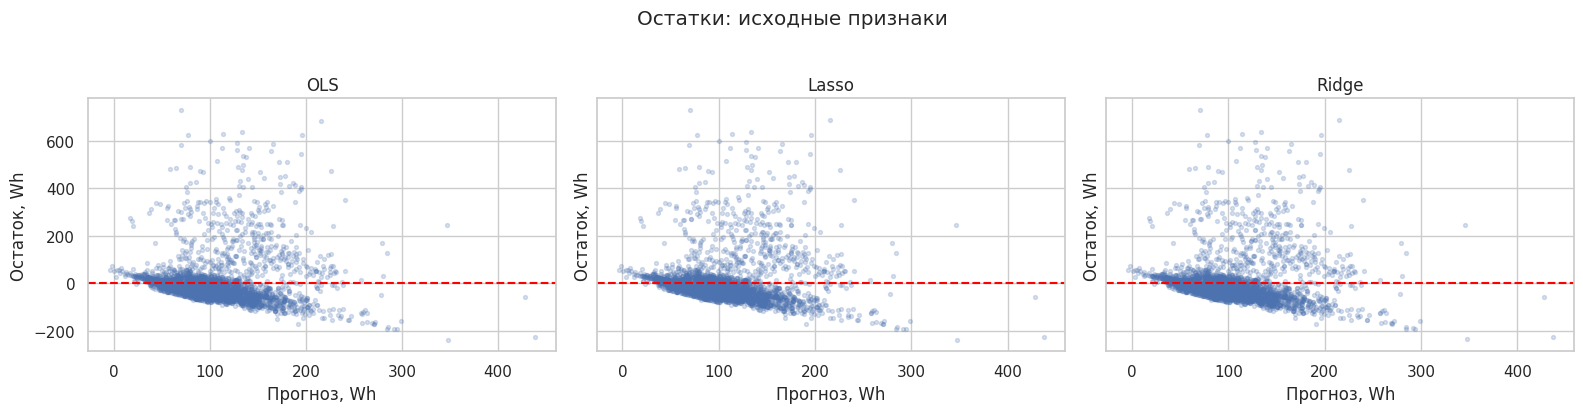

,Низкие прогнозы,Высокие прогнозы
OLS,44.97,143.80
Lasso,44.95,143.84
Ridge,44.94,143.90


In [8]:
def residuals(models, title, filename):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
    spread = {}
    for ax, (name, model) in zip(axes, models.items()):
        pred = model.predict(X_test)
        error = y_test.to_numpy() - pred
        ax.scatter(pred, error, s=8, alpha=.22)
        ax.axhline(0, color="red", linestyle="--")
        ax.set(title=name, xlabel="Прогноз, Wh", ylabel="Остаток, Wh")
        groups = pd.Series(error).groupby(pd.qcut(pred, 5, labels=False)).std()
        spread[name] = [groups.iloc[0], groups.iloc[-1]]
    fig.suptitle(title, y=1.03)
    show_plot(filename)
    return pd.DataFrame(spread, index=["Низкие прогнозы", "Высокие прогнозы"]).T

spread_before = residuals(base_models, "Остатки: исходные признаки", "03_residuals_original.png")
display(spread_before.round(2))

Большие положительные остатки соответствуют недооценённым пикам потребления.
Облако асимметрично, а разброс меняется с уровнем прогноза. Нижняя наклонная
граница частично объясняется положительностью цели: $e_i\geq\min(y)-\hat y_i$.
Поэтому вывод о неоднородности разброса основан также на таблице стандартных
отклонений, а не только на форме границы. Это диагностическое свидетельство
гетероскедастичности; временная зависимость наблюдений ограничивает строгие
статистические выводы.

Для OLS стандартное отклонение остатков увеличивается **с 44,97 Wh до 143,80 Wh** от нижней к верхней группе прогнозов. Это выраженная неоднородность разброса, совместимая с гетероскедастичностью.

#### 4.4. Стандартизация и метод главных компонент

PCA применяется **после StandardScaler** и обучается только на train.
Выбирается минимальное число компонент, сохраняющее не менее **95% дисперсии**
стандартизированных признаков. На графике каменистой осыпи показываются
собственные значения, рядом — накопленная доля дисперсии. В моделях PCA
находится внутри `Pipeline` и заново обучается в каждом фолде CV.

,VIF
PC1,1.0
PC2,1.0
PC3,1.0
PC4,1.0
PC5,1.0
PC6,1.0
PC7,1.0
PC8,1.0
PC9,1.0
PC10,1.0


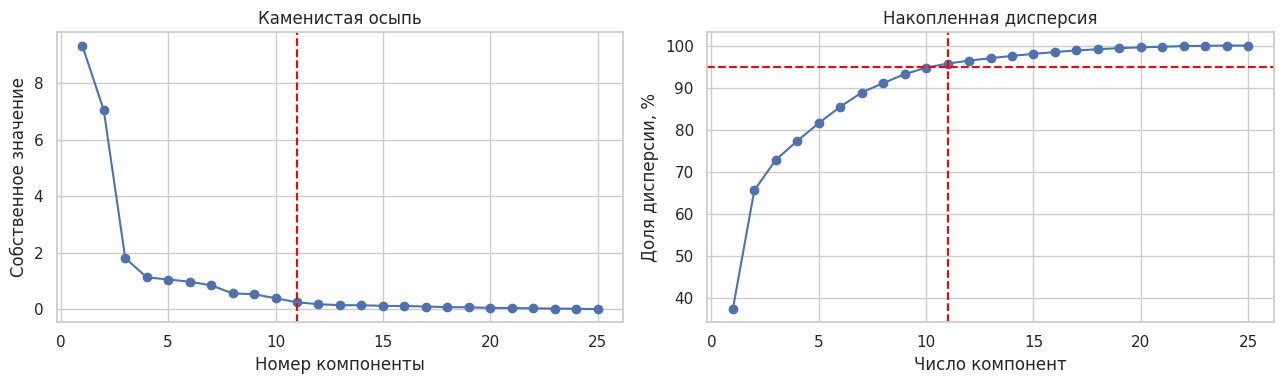

In [9]:
scaled = StandardScaler().fit_transform(X_train)
pca_full = PCA(svd_solver="full").fit(scaled)
cumulative = pca_full.explained_variance_ratio_.cumsum()
k95 = int(np.searchsorted(cumulative, .95) + 1)
components = pd.DataFrame(pca_full.transform(scaled)[:, :k95],
                          columns=[f"PC{i+1}" for i in range(k95)])
vif_after = vif(components)
display(vif_after.round(6).to_frame())
pd.concat({"Исходные": vif_before, "PCA": vif_after}, names=["Базис", "Признак"]).to_csv(OUT / "vif.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
numbers = np.arange(1, X.shape[1] + 1)
axes[0].plot(numbers, pca_full.explained_variance_, "o-")
axes[0].axvline(k95, color="red", linestyle="--")
axes[0].set(title="Каменистая осыпь", xlabel="Номер компоненты", ylabel="Собственное значение")
axes[1].plot(numbers, 100 * cumulative, "o-")
axes[1].axhline(95, color="red", linestyle="--")
axes[1].axvline(k95, color="red", linestyle="--")
axes[1].set(title="Накопленная дисперсия", xlabel="Число компонент", ylabel="Доля дисперсии, %")
show_plot("04_pca_scree.png")

Сохранённые компоненты ортогональны: их VIF на train равен 1 с точностью
вычислений. Таким образом, линейная мультиколлинеарность устранена одновременно
со снижением размерности. Это свойство относится к обучающей выборке PCA;
точная некоррелированность на новых данных не гарантируется. Сохранение 95%
дисперсии признаков не означает сохранения 95% информации о целевой переменной.

Для порога 95% достаточно **11 компонент из 25**: сохранено **95,71%** дисперсии. Десять компонент сохраняют лишь 94,74%, поэтому 11 — минимальное число по выбранному критерию. Размерность уменьшилась на **56%**, VIF всех компонент равен **1**.

#### 4.5. Повторное обучение и сравнение

Три регрессии повторно обучаются на главных компонентах. Разбиение данных,
CV-фолды, сетки `alpha` и метрики остаются прежними. Отличается только
добавление PCA после стандартизации. Тестовые результаты двух экспериментов
сравниваются в одной таблице и на графиках.

,Признаки,Модель,alpha,k,CV RMSE,CV σ RMSE,CV R²,"CV MAPE, %","RMSE, Wh",R²,"MAPE, %"
0,Исходные,OLS,NaN,25,94.5303,1.3236,0.1595,61.2417,91.1717,0.1694,62.9209
1,Исходные,Lasso,0.0100,25,94.5289,1.3283,0.1595,61.2180,91.1672,0.1694,62.8847
2,Исходные,Ridge,3.1623,25,94.5309,1.3257,0.1595,61.2129,91.1681,0.1694,62.8994
3,PCA,OLS,NaN,11,97.6162,1.5453,0.1038,63.4403,93.9758,0.1175,65.0733
4,PCA,Lasso,0.1000,11,97.6149,1.5465,0.1038,63.4196,93.9735,0.1175,65.0587
5,PCA,Ridge,31.6228,11,97.6153,1.5468,0.1038,63.4331,93.9745,0.1175,65.0661


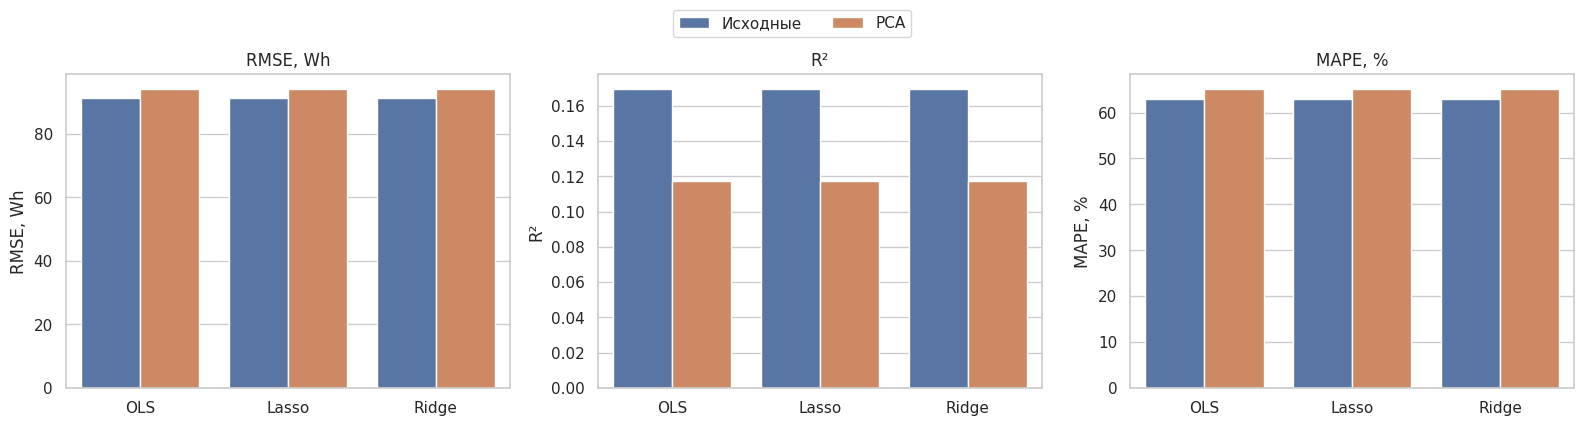

,"Δ RMSE, Wh",Δ R²,"Δ MAPE, %"
Модель,,,
OLS,2.8041,-0.0519,2.1524
Lasso,2.8062,-0.0519,2.1741
Ridge,2.8063,-0.0519,2.1667


In [10]:
pca_metrics, pca_models = assess_family(use_pca=True)
comparison = pd.concat([base_metrics, pca_metrics], ignore_index=True)
comparison.to_csv(OUT / "metrics.csv", index=False)
display(comparison.round(4))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["RMSE, Wh", "R²", "MAPE, %"]):
    sns.barplot(data=comparison, x="Модель", y=metric, hue="Признаки", ax=ax)
    ax.set(xlabel="", title=metric)
    ax.get_legend().remove()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center",
           bbox_to_anchor=(.5, 1.08), ncol=2)
show_plot("05_model_comparison.png")
metric_names = ["RMSE, Wh", "R²", "MAPE, %"]
delta = (pca_metrics.set_index("Модель")[metric_names]
         - base_metrics.set_index("Модель")[metric_names])
display(delta.rename(columns=lambda s: "Δ " + s).round(4))
predictions = pd.DataFrame({"y_true": y_test})
for basis, models in [("original", base_models), ("pca", pca_models)]:
    for name, model in models.items():
        predictions[f"{basis}_{name}"] = model.predict(X_test)
predictions.to_csv(OUT / "predictions.csv", index_label="row_id")

В таблице Δ вычисляется как «после PCA минус до PCA»: положительные ΔRMSE
и ΔMAPE означают ухудшение, положительное ΔR² — улучшение. По результатам
проверяется влияние снижения размерности, а не только устранение корреляций.
Предпочтительная конфигурация определяется по внешнему CV RMSE; небольшие
различия между методами не трактуются как статистически доказанное превосходство.

После PCA тестовый RMSE каждой регрессии вырос примерно **на 2,8 Wh**, R² снизился **с 0,169 до 0,118**, MAPE увеличился **с 62,9% до 65,1%**. По минимальному внешнему CV RMSE формально выбрана **Lasso на исходных признаках**, но она практически совпадает с OLS и Ridge. Усечение PCA удалило часть полезной для цели информации, хотя сохранило большую часть дисперсии X и устранило мультиколлинеарность.

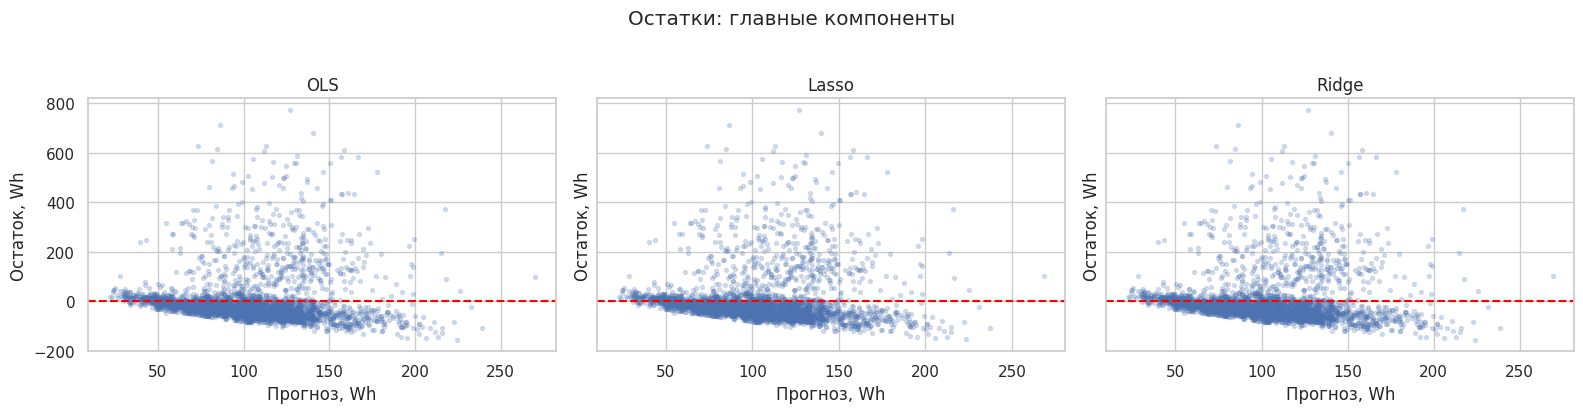

,Низкие прогнозы,Высокие прогнозы
OLS,36.74,136.33
Lasso,36.75,136.30
Ridge,36.73,136.32


In [11]:
spread_after = residuals(pca_models, "Остатки: главные компоненты", "06_residuals_pca.png")
display(spread_after.round(2))

После PCA сохраняются недооценка пиков и неодинаковый разброс ошибок.
Ортогонализация предикторов не обеспечивает гомоскедастичность:
она меняет пространство признаков, но не устраняет пропущенные нелинейные
зависимости и неоднородность режима работы приборов.

У OLS после PCA стандартное отклонение остатков растёт **с 36,74 Wh до 136,33 Wh** между крайними группами прогнозов. Гомоскедастичность после снижения размерности не наблюдается.

### 5. Заключение

1. Исследованы **19 735 измерений**; пропусков и дубликатов нет. После исключения даты и двух случайных контролей используются **25 числовых признаков**, train/test — **15 788/3947**.
2. Обнаружена сильная мультиколлинеарность: **17 признаков имеют VIF > 10**. Стандартизированный PCA сократил размерность до **11 компонент**, сохранил **95,71% дисперсии** и снизил VIF компонент до **1**.
3. По внешнему CV RMSE выбрана Lasso на исходных признаках: на тесте **RMSE = 91,17 Wh, R² = 0,1694, MAPE = 62,88%**. Отличия от OLS и Ridge малы. После PCA все три модели ухудшились: RMSE составил около **93,97 Wh**, R² — **0,1175**, MAPE — **65,1%**. Устранение мультиколлинеарности не обеспечило роста точности.
4. Остатки асимметричны, пики недооцениваются, а разброс растёт с уровнем прогноза. Диагностика указывает на гетероскедастичность до и после PCA. Основные причины ошибок — редкие пики, нелинейные зависимости и отсутствие подробных данных о поведении жильцов.

Для повышения точности можно отдельно исследовать взаимодействия признаков, доступные на момент прогноза лаги и нелинейные модели. Эти варианты в работе не обучались. Данные относятся к одному дому; случайное разбиение содержит соседние моменты времени в разных фолдах. Полученные оценки характеризуют восстановление потребления при известных текущих признаках и не доказывают качество прогноза будущих периодов.

### 6. Список источников

1. Candanedo L. M., Feldheim V., Deramaix D. **Data driven prediction models of energy use of appliances in a low-energy house.** Energy and Buildings. 2017. Vol. 140. P. 81–97. [DOI: 10.1016/j.enbuild.2017.01.083](https://doi.org/10.1016/j.enbuild.2017.01.083).
2. [Appliances Energy Prediction — Kaggle](https://www.kaggle.com/datasets/loveall/appliances-energy-prediction).
3. [Appliances Energy Prediction — UCI](https://archive.ics.uci.edu/dataset/374/appliances+energy+prediction). [DOI: 10.24432/C5VC8G](https://doi.org/10.24432/C5VC8G).
4. [Репозиторий автора датасета: LuisM78/Appliances-energy-prediction-data](https://github.com/LuisM78/Appliances-energy-prediction-data/tree/e3e4c27a4ae2b41b21f84b4c9ac2d822d3d0ace1). Источник использованного CSV и описания переменных.
5. НГТУ НЭТИ. **Линейная регрессия и факторный анализ.** Учебные слайды из предоставленного файла «Машинное обучение, регрессия и факторный анализ.pdf», слайды 33–43.
6. scikit-learn: [линейные модели](https://scikit-learn.org/stable/modules/linear_model.html), [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [кросс-валидация](https://scikit-learn.org/stable/modules/cross_validation.html).
7. statsmodels: [расчёт VIF](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html).

### 7. Приложение. Полный листинг программного кода

Полный код собран ниже в раскрывающемся блоке и в отдельном файле
[`lab1.py`](lab1.py). Кодовые ячейки notebook выполняются последовательно;
после каждой из них приведено markdown-пояснение.

<details>
<summary>Развернуть полный листинг Python</summary>

```python
from pathlib import Path
import hashlib
import json
import os
import warnings

os.environ.setdefault("MPLCONFIGDIR", str(Path(".cache/matplotlib").resolve()))
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import root_mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tools.tools import add_constant
from statsmodels.stats.outliers_influence import variance_inflation_factor
from threadpoolctl import threadpool_limits

warnings.filterwarnings("error", category=ConvergenceWarning)
thread_limiter = threadpool_limits(limits=1)
sns.set_theme(style="whitegrid", font="DejaVu Sans")
pd.set_option("display.max_columns", 12)
OUT = Path("results")
(OUT / "figures").mkdir(parents=True, exist_ok=True)

def show_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / "figures" / name, dpi=140, bbox_inches="tight")
    plt.show()
    plt.close()

source = json.loads(Path("data/source.json").read_text(encoding="utf-8"))
data_file = Path("data") / source["file"]
assert hashlib.sha256(data_file.read_bytes()).hexdigest() == source["sha256"]
raw = pd.read_csv(data_file, parse_dates=["date"])
display(raw.head(3))
display(pd.Series({"Строк": len(raw), "Столбцов": raw.shape[1],
                   "Пропусков": raw.isna().sum().sum(),
                   "Дубликатов строк": raw.duplicated().sum(),
                   "rv1 и rv2 совпадают": raw.rv1.equals(raw.rv2)}).to_frame("Значение"))
display(raw.Appliances.describe().to_frame("Appliances, Wh"))

numeric = raw.select_dtypes(include=np.number)
fig, axes = plt.subplots(6, 5, figsize=(17, 17))
for ax, column in zip(axes.flat, numeric.columns):
    ax.hist(numeric[column], bins=30, color="#3486a6")
    ax.set(title=column, ylabel="Частота")
for ax in axes.flat[len(numeric.columns):]:
    ax.axis("off")
fig.suptitle("Распределения числовых переменных, включая Appliances", y=1.01)
show_plot("01_distributions.png")

corr = numeric.corr()
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, square=True)
plt.title("Корреляции Пирсона: исходный набор")
show_plot("02_correlations.png")
target_corr = corr["Appliances"].drop("Appliances").sort_values(key=abs, ascending=False)
display(target_corr.head(6).to_frame("Корреляция с Appliances"))

clean = raw.dropna().drop_duplicates().copy()
X = clean.drop(columns=["date", "Appliances", "rv1", "rv2"])
y = clean["Appliances"]
assert y.gt(0).all()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, random_state=42)
display(pd.DataFrame({"Выборка": ["Train", "Test"],
                      "Строк": [len(X_train), len(X_test)], "Признаков": X.shape[1]}))

def vif(frame):
    matrix = add_constant(StandardScaler().fit_transform(frame))
    return pd.Series([variance_inflation_factor(matrix, i + 1) for i in range(frame.shape[1])],
                     index=frame.columns, name="VIF")

vif_before = vif(X_train)
display(vif_before.sort_values(ascending=False).round(2).to_frame())

outer_cv = KFold(n_splits=5, shuffle=True, random_state=42)
inner_cv = KFold(n_splits=3, shuffle=True, random_state=17)
scoring = {"RMSE": "neg_root_mean_squared_error", "R2": "r2",
           "MAPE": "neg_mean_absolute_percentage_error"}

def assess_family(use_pca=False):
    candidates = {
        "OLS": (LinearRegression(), {}),
        "Lasso": (Lasso(max_iter=50000), {"reg__alpha": np.logspace(-2, 2, 9)}),
        "Ridge": (Ridge(solver="svd"), {"reg__alpha": np.logspace(-3, 5, 17)}),
    }
    rows, fitted = [], {}
    for name, (regressor, grid) in candidates.items():
        steps = [("scale", StandardScaler())]
        if use_pca:
            steps.append(("pca", PCA(n_components=.95, svd_solver="full")))
        pipe = Pipeline(steps + [("reg", regressor)])
        search = GridSearchCV(pipe, grid, cv=inner_cv, scoring="neg_root_mean_squared_error",
                              n_jobs=1, error_score="raise")
        cv = cross_validate(search, X_train, y_train, cv=outer_cv, scoring=scoring,
                            n_jobs=1, error_score="raise")
        search.fit(X_train, y_train)
        fitted[name] = search.best_estimator_
        pred = fitted[name].predict(X_test)
        rows.append({
            "Признаки": "PCA" if use_pca else "Исходные", "Модель": name,
            "alpha": search.best_params_.get("reg__alpha", np.nan),
            "k": fitted[name]["pca"].n_components_ if use_pca else X.shape[1],
            "CV RMSE": -cv["test_RMSE"].mean(),
            "CV σ RMSE": cv["test_RMSE"].std(ddof=1),
            "CV R²": cv["test_R2"].mean(), "CV MAPE, %": -100 * cv["test_MAPE"].mean(),
            "RMSE, Wh": root_mean_squared_error(y_test, pred), "R²": r2_score(y_test, pred),
            "MAPE, %": 100 * mean_absolute_percentage_error(y_test, pred),
        })
    return pd.DataFrame(rows), fitted

base_metrics, base_models = assess_family()
display(base_metrics.round(4))

def residuals(models, title, filename):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
    spread = {}
    for ax, (name, model) in zip(axes, models.items()):
        pred = model.predict(X_test)
        error = y_test.to_numpy() - pred
        ax.scatter(pred, error, s=8, alpha=.22)
        ax.axhline(0, color="red", linestyle="--")
        ax.set(title=name, xlabel="Прогноз, Wh", ylabel="Остаток, Wh")
        groups = pd.Series(error).groupby(pd.qcut(pred, 5, labels=False)).std()
        spread[name] = [groups.iloc[0], groups.iloc[-1]]
    fig.suptitle(title, y=1.03)
    show_plot(filename)
    return pd.DataFrame(spread, index=["Низкие прогнозы", "Высокие прогнозы"]).T

spread_before = residuals(base_models, "Остатки: исходные признаки", "03_residuals_original.png")
display(spread_before.round(2))

scaled = StandardScaler().fit_transform(X_train)
pca_full = PCA(svd_solver="full").fit(scaled)
cumulative = pca_full.explained_variance_ratio_.cumsum()
k95 = int(np.searchsorted(cumulative, .95) + 1)
components = pd.DataFrame(pca_full.transform(scaled)[:, :k95],
                          columns=[f"PC{i+1}" for i in range(k95)])
vif_after = vif(components)
display(vif_after.round(6).to_frame())
pd.concat({"Исходные": vif_before, "PCA": vif_after}, names=["Базис", "Признак"]).to_csv(OUT / "vif.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
numbers = np.arange(1, X.shape[1] + 1)
axes[0].plot(numbers, pca_full.explained_variance_, "o-")
axes[0].axvline(k95, color="red", linestyle="--")
axes[0].set(title="Каменистая осыпь", xlabel="Номер компоненты", ylabel="Собственное значение")
axes[1].plot(numbers, 100 * cumulative, "o-")
axes[1].axhline(95, color="red", linestyle="--")
axes[1].axvline(k95, color="red", linestyle="--")
axes[1].set(title="Накопленная дисперсия", xlabel="Число компонент", ylabel="Доля дисперсии, %")
show_plot("04_pca_scree.png")

pca_metrics, pca_models = assess_family(use_pca=True)
comparison = pd.concat([base_metrics, pca_metrics], ignore_index=True)
comparison.to_csv(OUT / "metrics.csv", index=False)
display(comparison.round(4))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric in zip(axes, ["RMSE, Wh", "R²", "MAPE, %"]):
    sns.barplot(data=comparison, x="Модель", y=metric, hue="Признаки", ax=ax)
    ax.set(xlabel="", title=metric)
    ax.get_legend().remove()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center",
           bbox_to_anchor=(.5, 1.08), ncol=2)
show_plot("05_model_comparison.png")
metric_names = ["RMSE, Wh", "R²", "MAPE, %"]
delta = (pca_metrics.set_index("Модель")[metric_names]
         - base_metrics.set_index("Модель")[metric_names])
display(delta.rename(columns=lambda s: "Δ " + s).round(4))
predictions = pd.DataFrame({"y_true": y_test})
for basis, models in [("original", base_models), ("pca", pca_models)]:
    for name, model in models.items():
        predictions[f"{basis}_{name}"] = model.predict(X_test)
predictions.to_csv(OUT / "predictions.csv", index_label="row_id")

spread_after = residuals(pca_models, "Остатки: главные компоненты", "06_residuals_pca.png")
display(spread_after.round(2))
```

</details>